### Procesamiento de Lenguaje Natural I
# **Desafío 1**



In [1]:
%pip install numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


### Vectorización de texto y modelo de clasificación Naïve Bayes con el dataset 20 newsgroups

In [2]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.metrics import f1_score

Utilizamos **20newsgroups** por ser un dataset clásico de NLP ya viene incluido y formateado en sklearn

In [3]:
from sklearn.datasets import fetch_20newsgroups
import numpy as np

## Carga de datos

Cargamos los datos (ya separados de forma predeterminada en train y test)

El dataset 20 Newsgroups contiene aproximadamente 18 000 publicaciones de grupos de noticias distribuidas en 20 temas. Está dividido en dos subconjuntos: uno para entrenamiento (train set) y otro para pruebas (test set).

In [4]:
newsgroups_train = fetch_20newsgroups(subset='train', remove=('headers', 'footers', 'quotes'))
newsgroups_test = fetch_20newsgroups(subset='test', remove=('headers', 'footers', 'quotes'))


## Vectorización

Instanciamos un vectorizador.

Podemos ver diferentes parámetros de instanciación en la documentación de sklearn https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

In [5]:
tfidfvect = TfidfVectorizer()

En el atributo `data` accedemos al texto

In [6]:
print(newsgroups_train.data[0])

I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


In [7]:
print(newsgroups_train.target)

[7 4 4 ... 3 1 8]


Con la interfaz habitual de sklearn podemos ajustar el vectorizador (obtener el vocabulario y calcular el vector IDF) y transformar directamente los datos.

Podemos denominar `X_train` como la matriz documento-término.

In [8]:
X_train = tfidfvect.fit_transform(newsgroups_train.data)

Recordemos que las vectorizaciones por conteos son de tipo sparse, por ello sklearn convenientemente devuelve los vectores de documentos como matrices de tipo sparse.

In [9]:
print(type(X_train))
print(f'shape: {X_train.shape}')
print(f'Cantidad de documentos: {X_train.shape[0]}')
print(f'Tamaño del vocabulario (dimensionalidad de los vectores): {X_train.shape[1]}')

<class 'scipy.sparse._csr.csr_matrix'>
shape: (11314, 101631)
Cantidad de documentos: 11314
Tamaño del vocabulario (dimensionalidad de los vectores): 101631


Una vez ajustado el vectorizador, podemos acceder a atributos como el vocabulario aprendido. Es un diccionario que va de términos a índices.

El índice es la posición en el vector de documento.

In [10]:
tfidfvect.vocabulary_['car']

25775

Probamos con una palbra que no está en el documento.

In [11]:
# tfidfvect.vocabulary_['cocoliso']

Es muy útil tener el diccionario opuesto que va de índices a términos

In [12]:
idx2word = {v: k for k,v in tfidfvect.vocabulary_.items()}

En `y_train` guardamos los targets que son enteros

In [13]:
y_train = newsgroups_train.target
y_train[:10]

array([ 7,  4,  4,  1, 14, 16, 13,  3,  2,  4])

Hay 20 clases correspondientes a los 20 grupos de noticias

In [14]:
print(f'clases {np.unique(newsgroups_test.target)}')
newsgroups_test.target_names

clases [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]


['alt.atheism',
 'comp.graphics',
 'comp.os.ms-windows.misc',
 'comp.sys.ibm.pc.hardware',
 'comp.sys.mac.hardware',
 'comp.windows.x',
 'misc.forsale',
 'rec.autos',
 'rec.motorcycles',
 'rec.sport.baseball',
 'rec.sport.hockey',
 'sci.crypt',
 'sci.electronics',
 'sci.med',
 'sci.space',
 'soc.religion.christian',
 'talk.politics.guns',
 'talk.politics.mideast',
 'talk.politics.misc',
 'talk.religion.misc']

## Similaridad de documentos

Veamos similaridad de documentos. Tomemos algún documento

In [15]:
idx = 4811
print(newsgroups_train.data[idx])

THE WHITE HOUSE

                  Office of the Press Secretary
                   (Pittsburgh, Pennslyvania)
______________________________________________________________
For Immediate Release                         April 17, 1993     

             
                  RADIO ADDRESS TO THE NATION 
                        BY THE PRESIDENT
             
                Pittsburgh International Airport
                    Pittsburgh, Pennsylvania
             
             
10:06 A.M. EDT
             
             
             THE PRESIDENT:  Good morning.  My voice is coming to
you this morning through the facilities of the oldest radio
station in America, KDKA in Pittsburgh.  I'm visiting the city to
meet personally with citizens here to discuss my plans for jobs,
health care and the economy.  But I wanted first to do my weekly
broadcast with the American people. 
             
             I'm told this station first broadcast in 1920 when
it reported that year's presidential elec

Medimos la similaridad coseno con todos los documentos de train

In [16]:
cossim = cosine_similarity(X_train[idx], X_train)[0]

Podemos ver los valores de similaridad ordenados de mayor a menor

In [17]:
np.sort(cossim)[::-1]

array([1.        , 0.70930477, 0.67474953, ..., 0.        , 0.        ,
       0.        ])

Después vemos a qué documentos corresponden

In [18]:
np.argsort(cossim)[::-1]

array([ 4811,  6635,  4253, ...,  1534, 10055,  4750], dtype=int64)

Obtenemos los 5 documentos más similares:

In [19]:
mostsim = np.argsort(cossim)[::-1][1:6]
print(mostsim)

[6635 4253 3596 4271 3746]


El documento original pertenece a la clase:

In [20]:
newsgroups_train.target_names[y_train[idx]]

'talk.politics.misc'

Revisamos las clases de los 5 más similares:

In [21]:
for i in mostsim:
  print(newsgroups_train.target_names[y_train[i]])

talk.politics.misc
talk.politics.misc
talk.politics.misc
talk.politics.misc
talk.politics.misc


### Modelo de clasificación Naïve Bayes

Instanciamos el modelo de clasificación Naive Bayes y lo entrenamos con sklearn

In [22]:
clf = MultinomialNB()
clf.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](20,)","[480.,584.,591.,...,564.,465.,377.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](20,)","[-3.16,-2.96,-2.95,...,-3. ,-3.19,-3.4 ]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int32](20,)","[ 0, 1, 2,...,17,18,19]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](20, 101631)","[[0. ,0.94,0. ,...,0. ,0. ,0. ], [1.39,0.6 ,0. ,...,0. ,0. ,0. ], [0.95,0.14,0. ,...,0. ,0. ,0. ], ..., [0.42,2.9 ,0.04,...,0. ,0. ,0. ], [0.61,1.36,0. ,...,0. ,0. ,0. ], [0.03,0.38,0. ,...,0. ,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](20, 101631)","[[-11.56,-10.9 ,-11.56,...,-11.56,-11.56,-11.56], [-10.69,-11.1 ,-11.56,...,-11.56,-11.56,-11.56], [-10.9 ,-11.44,-11.57,...,-11.57,-11.57,-11.57], ..., [-11.22,-10.21,-11.54,...,-11.57,-11.57,-11.57], [-11.09,-10.7 ,-11.56,...,-11.56,-11.56,-11.56], [-11.53,-11.23,-11.56,...,-11.56,-11.56,-11.56]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,101631


Ya tenemos nuestro vectorizador ya ajustado en train, vectorizamos los textos
del conjunto de test.

In [23]:
X_test = tfidfvect.transform(newsgroups_test.data)
y_test = newsgroups_test.target
y_pred =  clf.predict(X_test)

El F1-score es una métrica adecuada para evaluar el desempeño de modelos de clasificación, especialmente cuando existe desbalance entre clases.

* El promediado macro calcula el promedio del F1-score de cada clase, otorgando el mismo peso a todas las clases.
* El promediado micro calcula las métricas de forma global considerando todas las predicciones; en problemas de clasificación multiclase suele ser equivalente a la accuracy, por lo que no es la mejor métrica cuando el dataset está desbalanceado.

In [24]:
f1_score(y_test, y_pred, average='macro')

0.5854345727938506

In [25]:
print(y_pred)

[15  1 15 ... 15  3 15]


---

## **Consigna del Desafío 1**
**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado.**



**1. Vectorizar documentos**
* Tomar 5 documentos al azar y medir similaridad con el resto de los documentos.
Estudiar los 5 documentos más similares de cada uno analizar si tiene sentido
la similaridad según el contenido del texto y la etiqueta de clasificación.

**2. Construir un modelo de clasificación por prototipos (tipo zero-shot).**
* Clasificar los documentos de un conjunto de test comparando cada uno con todos los de entrenamiento y asignar la clase al label del documento del conjunto de entrenamiento con mayor similaridad.

**3. Entrenar modelos de clasificación Naïve Bayes para maximizar el desempeño de clasificación**

* F1-Score Macro en el conjunto de datos de test. Considerar cambiar parámetros
de instanciación del vectorizador y los modelos y probar modelos de Naïve Bayes Multinomial y ComplementNB.

**NO cambiar el hiperparámetro ngram_range de los vectorizadores**.

**4. Transponer la matriz documento-término.**
* De esa manera se obtiene una matriz término-documento que puede ser interpretada como una colección de vectorización de palabras.
* Estudiar ahora similaridad entre palabras tomando 5 palabras y estudiando sus 5 más similares.

**Elegir las palabras MANUALMENTE para evitar la aparición de términos poco interpretables**.


## Punto 1: Vectorizar documentos



In [26]:
## Tomamos 5 documentos al azar
ids = [1234, 333, 777, 6767, 1]

# Hago un print de sus clases
for idx in ids:
    class_id = newsgroups_train.target[idx]
    print(newsgroups_train.target_names[class_id])

talk.politics.guns
comp.os.ms-windows.misc
rec.sport.baseball
misc.forsale
comp.sys.mac.hardware


## Analisis por documento por selector de id

Para no cargar el notebook, segun el id de documento que se elija, se va mostrando un analisis u otro.

In [27]:
## Analizo el contenido de alguno de los documentos
selected_id = ids[4]

print("categoria del documento elegido: ", selected_id, " ", newsgroups_train.target_names[y_train[selected_id]])
## Busco por similitud coseno los ids de los 5 documentos mas similares
cossim = cosine_similarity(X_train[selected_id], X_train)[0]
mostsim = np.argsort(cossim)[::-1][1:6]
for i in mostsim:
  print("categoria del documento: ",i, " ", newsgroups_train.target_names[y_train[i]])

categoria del documento elegido:  1   comp.sys.mac.hardware
categoria del documento:  6399   comp.sys.mac.hardware
categoria del documento:  9130   comp.sys.mac.hardware
categoria del documento:  4693   comp.sys.mac.hardware
categoria del documento:  1270   comp.sys.mac.hardware
categoria del documento:  9921   comp.sys.mac.hardware


In [28]:
# Los analizamos - todos corresponden a la misma categoria
print("DOCUMENTO BASE\n")
print(newsgroups_train.data[selected_id])
print("\n----- FIN -----\n")
for doc in mostsim:
    print("----- INICIO DOCUMENTO ----- id: ", doc, " \n")
    print(newsgroups_train.data[doc])
    print("\n----- SIG. DOCUMENTO -----\n")

DOCUMENTO BASE

A fair number of brave souls who upgraded their SI clock oscillator have
shared their experiences for this poll. Please send a brief message detailing
your experiences with the procedure. Top speed attained, CPU rated speed,
add on cards and adapters, heat sinks, hour of usage per day, floppy disk
functionality with 800 and 1.4 m floppies are especially requested.

I will be summarizing in the next two days, so please add to the network
knowledge base if you have done the clock upgrade and haven't answered this
poll. Thanks.

----- FIN -----

----- INICIO DOCUMENTO ----- id:  6399  

I am continuing to collect user results to produce a more comprehensive
report on IIsi clock oscillator upgrades. I you have attempted the modification
please drop me a note with details of your experience. The more reports 
obtained, the more accurate the numbers I will generate.

If possible, please include the following:
  1) Top speed achieved
  2) System configuration at top Mhz settin

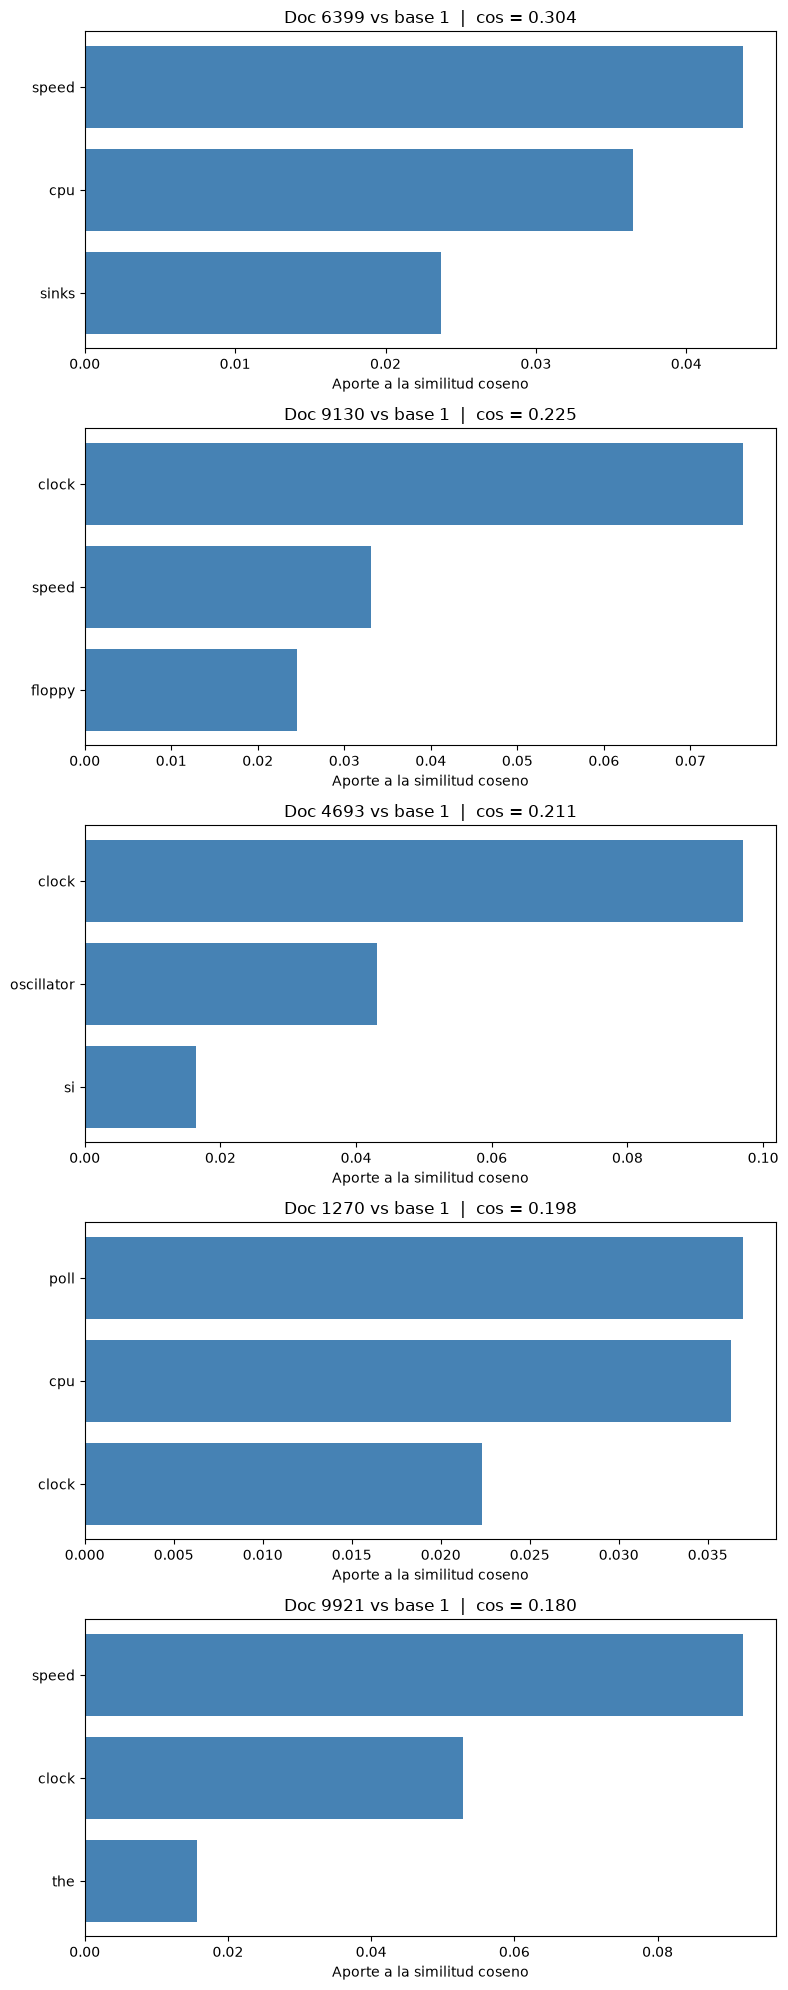

In [29]:
import numpy as np
import matplotlib.pyplot as plt

vocab = tfidfvect.get_feature_names_out()
base = X_train[selected_id]
top_n = 3

fig, axes = plt.subplots(len(mostsim), 1, figsize=(8, 4 * len(mostsim)))
axes = np.atleast_1d(axes)

for ax, doc in zip(axes, mostsim):
    # aporte de cada palabra = tfidf_base * tfidf_doc
    contrib = base.multiply(X_train[doc]).toarray().ravel()
    top = np.argsort(contrib)[::-1][:top_n]
    top = top[contrib[top] > 0]

    ax.barh(vocab[top][::-1], contrib[top][::-1], color="steelblue")
    ax.set_title(f"Doc {doc} vs base {selected_id}  |  cos = {contrib.sum():.3f}")
    ax.set_xlabel("Aporte a la similitud coseno")

plt.tight_layout()
plt.show()

In [30]:
from IPython.display import Markdown, display

analysis = {
    1234: """
## Documento 1234

El documento es de categoria talk.politics.guns, el texto habla (en resumidas cuentas) sobre que hay que reducir la criminalidad pero no las armas de fuego. Luego, hace una descripcion de que armas usan los criminales y como las emplean.
Dentro de los 5 documentos mas similares, 4 son de la misma categoria salvo el de id 10428 que es de categoria talk.politics.misc, que es el tercero con mayor similitud coseno. El mismo habla mayormente de la criminalidad en si, pero hace una minima mencion al uso de armas dentro de los crimenes. Es probable que en este texto aparezcan ciertos terminos con mayor frecuencia al igual que en el texto base, lo que hace que la similitud coseno tienda a ser mayor mas alla de que la clase del texto sea distinta.
Luego, el resto de documentos si hace referencia a las armas en si y su uso, junto con la idea de criminalidad.

En las palabras que componen los documentos, vemos que "gun", "guns", "knife" y "crime" son las que mas aportan a la similitud coseno.
""",
    333: """
### Documento 333
En este documento, la categoria es comp.os.ms-windows.misc, sin embargo, los documentos con mayor similitud coseno tienen clases distintas: talk.politics.misc, rec.sport.baseball, misc.forsale y comp.sys.mac.hardware.
Esto es debido a que las palabras que mayor aportan a la similitud coseno, son "mail", "thanks", "please".

El documento base es un correo de pocas palabras. Luego, los otros documentos parecieran notas de diversos temas.
Mas alla de que la clase sea distinta u el contenido apunte a algun topico en particular, hay muchas palabras que se comparten entre documentos.
""",

    777: """
### Documento 777
Este documento tiene categoria rec.sport.baseball y los documentos con mayor similitud coseno tambien. En todos los documentos hay un fuerte aporte de los terminos "rbi", "runs" y "team".
En cada documento, se hace enfasis en la metrica RBI, es decir, todos hablan de alguna forma de lo mismo. Es logica la similitud.
""",

    6767: """
### Documento 6767
El documento es de categoria misc.forsale, es un aviso corto de venta de un "super scope 6" con CRT, cajas e instrucciones, con envio incluido.
Dentro de los 5 documentos mas similares, 2 son de la misma categoria (10757 y 10001), ambos avisos de venta. El 10757 comparte "scope" y "sale", aunque se trata de un osciloscopio y no del mismo producto. El 10001 comparte "shipping", "included" y "used".

Los documentos 2429 (comp.graphics) y 8719 (sci.med) solo contienen "Hello,". Como tienen un unico termino, toda la similitud coseno viene de "hello", que tambien aparece en el documento base. No hay relacion de contenido.
El documento 5284 (comp.graphics) aparece por el termino "CRT", que es poco frecuente y tiene un peso alto, aunque en el base se refiere a un televisor y en este a un registro de video.

En este caso en particular, una sola palabra alcanzo para que la similitud coseno sea alta, mas alla de la clase o el contenido.
""",

    1: """
### Documento 1
El documento es de categoria comp.sys.mac.hardware, es una encuesta sobre la modificacion del oscilador de reloj en Macs.
Los 5 documentos mas similares son de la misma categoria. Los documentos 6399 y 1270 son practicamente la misma encuesta o convocatoria a reportar resultados. Los documentos 9130 y 4693 cuentan experiencias concretas cambiando el oscilador (en SI y Quadra). El 9921 es el menos relacionado: habla de velocidad de procesadores y memoria en general, sin mencionar la modificacion.

En las palabras que componen los documentos, "clock", "oscillator", "speed", "si" y "cpu" son las que mas aportan a la similitud coseno.
Es logica la similitud, todos hablan del mismo tema con vocabulario muy especifico.
"""
}

def show_analysis(doc_id):
    texto = analysis.get(doc_id, f"_No hay nota para el documento {doc_id}_")
    display(Markdown(texto))

show_analysis(selected_id)




### Documento 1
El documento es de categoria comp.sys.mac.hardware, es una encuesta sobre la modificacion del oscilador de reloj en Macs.
Los 5 documentos mas similares son de la misma categoria. Los documentos 6399 y 1270 son practicamente la misma encuesta o convocatoria a reportar resultados. Los documentos 9130 y 4693 cuentan experiencias concretas cambiando el oscilador (en SI y Quadra). El 9921 es el menos relacionado: habla de velocidad de procesadores y memoria en general, sin mencionar la modificacion.

En las palabras que componen los documentos, "clock", "oscillator", "speed", "si" y "cpu" son las que mas aportan a la similitud coseno.
Es logica la similitud, todos hablan del mismo tema con vocabulario muy especifico.


## Punto 2: Clasificador de documentos por prototipos

In [31]:
def classify_by_cossim(X):
    preds = []
    for start in range(0, X.shape[0], 500):
        sim = cosine_similarity(X[start:start+500], X_train)
        preds.append(y_train[sim.argmax(axis=1)])
    return np.concatenate(preds)

In [32]:
y_pred_cossim = classify_by_cossim(X_test)
print(f1_score(y_test, y_pred_cossim, average='macro'))

0.5049911553681621


Para el clasificador implementado a partir de tomar la clase de la similitud coseno mas cercana, dio una metrica bastante regular. Ademas, este clasificador podria ser propenso a ruido si hubiese algun documento que por algun motivo tuviese una similitud coseno muy alta por casualidad de los terminos que usa. No es recomendable

## Punto 3: Entrenamiento de clasificadores

In [33]:
tfidfvect = TfidfVectorizer(sublinear_tf=True)
X_train = tfidfvect.fit_transform(newsgroups_train.data)
X_test = tfidfvect.transform(newsgroups_test.data)

In [34]:
## Tenemos el y_pred del clasificador por similitud coseno
y_pred_cossim = classify_by_cossim(X_test)
print(f1_score(y_test, y_pred_cossim, average='macro'))

0.5684951828899392


In [35]:
compnb = ComplementNB(alpha=0.325)
compnb.fit(X_train, y_train)
y_pred_compnb =  compnb.predict(X_test)
print("Clasificador ComplementNB", f1_score(y_test, y_pred_compnb, average='macro'))

Clasificador ComplementNB 0.6992631334497801


In [36]:
clf = MultinomialNB(alpha=0.027)
clf.fit(X_train, y_train)
y_pred_clf =  clf.predict(X_test)
print("Clasificador MultinomialNB", f1_score(y_test, y_pred_clf, average='macro'))

Clasificador MultinomialNB 0.6744047921709757


Con sublinear_tf en True y ajustando hiperparametros a ojo, el mejor modelo fue ComplementNB, seguido de MultinomialNB y el de similitud coseno. No es una métrica del todo buena, hay clases muy parecidas entre si que podrian confundirse.

## Punto 4: trasponer la matriz documento-termino

Genero un nuevo tfidfVectorizer, donde saco stopwords para mejorar el analisis. Realizo un fit_transform para obtener el vocabulario que voy a estar usando y lo transpongo para tener la matriz termino-documento. Luego, vuelvo a generar el idx2word para que quede actualizado con mi vocabulario

In [37]:

tfidfvect = TfidfVectorizer(sublinear_tf=True, stop_words='english')
X_train = tfidfvect.fit_transform(newsgroups_train.data)
transposed = X_train.T
idx2word = {v: k for k,v in tfidfvect.vocabulary_.items()}

ids = [tfidfvect.vocabulary_['horse'], tfidfvect.vocabulary_['ball'], tfidfvect.vocabulary_['stone'], tfidfvect.vocabulary_['water'], tfidfvect.vocabulary_['god']]


for idx in ids:
    print("palabra elegida: ", idx, " ", idx2word[idx])
    cossim = cosine_similarity(transposed[idx], transposed)[0]
    mostsim = np.argsort(cossim)[::-1][1:6]
    for i in mostsim:
        print("Palabra: ", i, " ", idx2word[i])
    print('\n')

palabra elegida:  47221   horse
Palabra:  76933   reins
Palabra:  71721   plow
Palabra:  76925   reining
Palabra:  76912   rein
Palabra:  48922   illuminatti


palabra elegida:  21447   ball
Palabra:  79391   runners
Palabra:  86648   swing
Palabra:  79390   runner
Palabra:  77068   relieves
Palabra:  74059   puzzled


palabra elegida:  85311   stone
Palabra:  32952   derose
Palabra:  31030   cusps
Palabra:  30859   cubic
Palabra:  85073   steinfeldt
Palabra:  38203   evers


palabra elegida:  95614   water
Palabra:  85032   steam
Palabra:  89442   towers
Palabra:  71574   plants
Palabra:  34313   diverted
Palabra:  29707   cooling


palabra elegida:  43733   god
Palabra:  52019   jesus
Palabra:  39317   faith
Palabra:  22649   bible
Palabra:  27138   christ
Palabra:  57291   lord




Analizando palabra por palabra:
* God se relaciona con jesus, faith, bible, christ y lord. Lo cual tiene sentido, son palabras dentro de un mismo contexto religioso y deben encontrarse concentradas en muchos documentos en común.
* Ball aparece relacionado con runners, swing, runner, vimos en uno de los documentos que seleccionamos que aparecen mucho en topicos de deporte. Luego aparecen relieves y puzzled que parecieran ser ruido.
* Horse viene acompañada de reins, plow y rein. Aparece illuminatti, lo cual es claramente ruido.
* Water viene acompañado de steam, towers, plants y cooling, pareciera que hay documentos hablando de torres de refrigeración de alguna planta o central. Diverted pareciera ser ruido.
* Stone, particularmente podría hacer referencia tanto al objeto como a un nombre propio. En este caso, derose, cusps y cubic dan a entender que es un apellido en algún documento de gráficos, no la piedra.


En general, las palabras más comunes y de un tema puntual (como god) dan resultados con sentido. Las que aparecen como ruido parecen ser palabras que están en muy pocos documentos, por lo que si coinciden con alguno de la palabra elegida la similitud sale alta.

